### Продвинутые методы

#### Doubly-robust Estimator

Doubly Robust Estimation — это способ объединения propensity score и линейной регрессии таким образом, что вам не придется полагаться ни на один из них.

Чтобы понять, как это работает, давайте рассмотрим эксперимент с установкой на рост. Это рандомизированное исследование, проводимое в государственных средних школах США, целью которого является изучение влияния установки на рост. Суть его заключается в том, что учащиеся получают от школы семинар, призванный привить им установку на рост. Затем, в годы обучения в колледже, с ними проводятся повторные занятия, чтобы оценить их успеваемость. Этот показатель был объединен в балл успеваемости и стандартизирован. Реальные данные этого исследования не публикуются в целях сохранения конфиденциальности учащихся. Однако у нас есть смоделированный набор данных с теми же статистическими свойствами, предоставленный Эйти и Вейджером, поэтому мы будем использовать его.

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from matplotlib import style
from matplotlib import pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LinearRegression

%matplotlib inline

style.use("fivethirtyeight")
pd.set_option("display.max_columns", 6)

data = pd.read_csv(".data/learning_mindset.csv")
data.sample(5, random_state=5)

,schoolid,intervention,achievement_score,...,school_ethnic_minority,school_poverty,school_size
259,73,1,1.480828,...,-0.515202,-0.169849,0.173954
3435,76,0,-0.987277,...,-1.310927,0.224077,-0.426757
9963,4,0,-0.152340,...,0.875012,-0.724801,0.761781
4488,67,0,0.358336,...,0.315755,0.054586,1.862187
2637,16,1,1.360920,...,-0.033161,-0.982274,1.591641


Несмотря на рандомизацию исследования, данные, по всей видимости, не лишены искажений. Одна из возможных причин заключается в том, что экспериментальная переменная измеряется по факту посещения семинара студентом. Таким образом, хотя возможность участия была случайной, участие – нет. В данном случае мы имеем дело со случаем несоблюдения требований. Одним из доказательств этого является то, как ожидания студента относительно успеха коррелируют с участием в семинаре. Студенты с более высокими, по их собственным оценкам, ожиданиями с большей вероятностью посещали семинар, посвящённый мышлению роста.

Как мы уже знаем, мы можем внести поправку, используя линейную регрессию или оценивая модель propensity score с помощью логистической регрессии. Однако перед этим нам необходимо преобразовать категориальные переменные в фиктивные.

In [ ]:
categ = ["ethnicity", "gender", "school_urbanicity"]
cont = ["school_mindset", "school_achievement", "school_ethnic_minority", "school_poverty", "school_size"]

data_with_categ = pd.concat([
    data.drop(columns=categ), # dataset without the categorical features
    pd.get_dummies(data[categ], columns=categ, drop_first=False) # categorical features converted to dummies
], axis=1)

**Двойная робастная оценка**

Двойная робастная оценка представляет собой композицию модели propensity score и линейной регрессии, которая описывается следующими формулами:

$
\hat{ATE} = \frac{1}{N}\sum \bigg( \dfrac{T_i(Y_i - \hat{\mu_1}(X_i))}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg) - \frac{1}{N}\sum \bigg( \dfrac{(1-T_i)(Y_i - \hat{\mu_0}(X_i))}{1-\hat{P}(X_i)} + \hat{\mu_0}(X_i) \bigg)
$

где $\hat{P}(x)$ — оценка propensity score, $\hat{\mu_1}(x)$ — это оценка $E[Y|X, T=1]$, а $\hat{\mu_0}(x)$ — это оценка $E[Y|X, T=0]$. Как вы, возможно, уже догадались, первая часть двойной робастной оценки оценивает $E[Y_1]$, а вторая — $E[Y_0]$. Давайте рассмотрим первую часть, поскольку все те же соображения применимы и ко второй части по аналогии.

Она называется двойной робастной, потому что для неё требуется только одна из моделей, $\hat{P}(x)$ или $\hat{\mu}(x)$, которая должна быть правильно задана. Чтобы убедиться в этом, рассмотрим первую часть, оценивающую $E[Y_1]$.

$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_i(Y_i - \hat{\mu_1}(X_i))}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg)
$

Предположим, что $\hat{\mu_1}(x)$ верна. Если модель propensity score неверна, нам не о чем беспокоиться. Потому что если $\hat{\mu_1}(x)$ верна, то $E[T_i(Y_i - \hat{\mu_1}(X_i))]=0$. Это связано с тем, что умножение на $T_i$ выбирает только воздействаованные объекты, а остаток $\hat{\mu_1}$ по ним по определению имеет нулевое среднее значение. Это сводит всё к $\hat{\mu_1}(X_i)$, которая, согласно предположению, верно оценена $E[Y_1]$. Итак, видите, будучи верной, $\hat{\mu_1}(X_i)$ сводит на нет нерелевантность модели propensity score. Мы можем применить те же рассуждения для понимания оценки $E[Y_0]$.

Как видим, ошибка в оценке склонности приводит к небольшим, но незначительным, отклонениям в результатах ATE. Это относится к случаю, когда модель propensity score неверна, а модель исхода верна. А как насчёт другой ситуации? Переставим некоторые члены.

$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_i(Y_i - \hat{\mu_1}(X_i))}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg)
$

$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_iY_i}{\hat{P}(X_i)} - \dfrac{T_i\hat{\mu_1}(X_i)}{\hat{P}(X_i)} + \hat{\mu_1}(X_i) \bigg)
$

$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_iY_i}{\hat{P}(X_i)} - \bigg(\dfrac{T_i}{\hat{P}(X_i)} - 1\bigg) \hat{\mu_1}(X_i) \bigg)
$

$
\hat{E}[Y_1] = \frac{1}{N}\sum \bigg( \dfrac{T_iY_i}{\hat{P}(X_i)} - \bigg(\dfrac{T_i - \hat{P}(X_i)}{\hat{P}(X_i)}\bigg) \hat{\mu_1}(X_i) \bigg)
$

Теперь предположим, что propensity score $\hat{P}(X_i)$ задана корректно. В этом случае $E[T_i - \hat{P}(X_i)]=0$, что исключает часть, зависящую от $\hat{\mu_1}(X_i)$. Это сводит дважды робастную оценку к оценке с весовым propensity score $\frac{T_iY_i}{\hat{P}(X_i)}$, которая верна по предположению. Таким образом, даже если $\hat{\mu_1}(X_i)$ неверна, оценка всё равно будет верной при условии, что propensity score задан корректно.

In [ ]:
def doubly_robust(df, X, T, Y):
    ps = LogisticRegression(C=1e6, max_iter=1000).fit(df[X], df[T]).predict_proba(df[X])[:, 1]
    mu0 = LinearRegression().fit(df.query(f"{T}==0")[X], df.query(f"{T}==0")[Y]).predict(df[X])
    mu1 = LinearRegression().fit(df.query(f"{T}==1")[X], df.query(f"{T}==1")[Y]).predict(df[X])
    return (
        np.mean(df[T]*(df[Y] - mu1)/ps + mu1) -
        np.mean((1-df[T])*(df[Y] - mu0)/(1-ps) + mu0)
    )

In [ ]:
from joblib import Parallel, delayed # for parallel processing

T = 'intervention'
Y = 'achievement_score'
X = data_with_categ.columns.drop(['schoolid', T, Y])

est = doubly_robust(data_with_categ, X, T, Y)

np.random.seed(88)
bootstrap_sample = 1000
ates = Parallel(n_jobs=-1)(delayed(doubly_robust)(data_with_categ.sample(frac=1, replace=True), X, T, Y)
                          for _ in range(bootstrap_sample))
ates = np.array(ates)

print(f"Estimate of ATE: {est}")
print(f"Original ATE 95% CI: [{round(np.percentile(ates, 2.5),4)} : {round(np.percentile(ates, 97.5),4)}]")

Estimate of ATE: 0.3984698280008528
Original ATE 95% CI: [0.3537 : 0.4198]


Я заменил логистическую регрессию, оценивающую propensity score, случайной равномерной переменной, принимающей значения от 0,1 до 0,9 (я не хочу, чтобы очень малые веса увеличивали дисперсию показателя склонности). Поскольку это случайная величина, она никак не может быть хорошей моделью для оценки показателя склонности, но мы увидим, что дважды робастная оценка всё же даёт оценку, очень близкую к той, которая была получена при оценке propensity score с помощью логистической регрессии.

In [ ]:
from sklearn.linear_model import LogisticRegression, LinearRegression

def doubly_robust_wrong_ps(df, X, T, Y):
    # wrong PS model
    np.random.seed(654)
    ps = np.random.uniform(0.1, 0.9, df.shape[0])
    mu0 = LinearRegression().fit(df.query(f"{T}==0")[X], df.query(f"{T}==0")[Y]).predict(df[X])
    mu1 = LinearRegression().fit(df.query(f"{T}==1")[X], df.query(f"{T}==1")[Y]).predict(df[X])
    return (
        np.mean(df[T]*(df[Y] - mu1)/ps + mu1) -
        np.mean((1-df[T])*(df[Y] - mu0)/(1-ps) + mu0)
    )

In [ ]:
est = doubly_robust_wrong_ps(data_with_categ, X, T, Y)

np.random.seed(88)
parallel_fn = delayed(doubly_robust_wrong_ps)
wrong_ps = Parallel(n_jobs=4)(parallel_fn(data_with_categ.sample(frac=1, replace=True), X, T, Y)
                              for _ in range(bootstrap_sample))
wrong_ps = np.array(wrong_ps)

print(f"Estimate of ATE: {est}")

print(f"Original ATE 95% CI: [{round(np.percentile(ates, 2.5),4)} : {round(np.percentile(ates, 97.5),4)}]")
print(f"Wrong PS ATE 95% CI: [{round(np.percentile(wrong_ps, 2.5),4)} : {round(np.percentile(wrong_ps, 97.5),4)}]")

Estimate of ATE: 0.3797085235740763
Original ATE 95% CI: [0.3537 : 0.4198]
Wrong PS ATE 95% CI: [0.3385 : 0.4328]


В приведённом ниже коде я заменил обе модели регрессии случайной нормальной переменной. Несомненно, $\hat{\mu}(X_i)$ задана **некорректно**. Тем не менее, мы увидим, что дважды робастная оценка всё ещё даёт тот же $\hat{ATE}$, что и раньше.

In [ ]:
from sklearn.linear_model import LogisticRegression, LinearRegression

def doubly_robust_wrong_model(df, X, T, Y):
    np.random.seed(654)
    ps = LogisticRegression(C=1e6, max_iter=1000).fit(df[X], df[T]).predict_proba(df[X])[:, 1]

    # wrong mu(x) model
    mu0 = np.random.normal(0, 1, df.shape[0])
    mu1 = np.random.normal(0, 1, df.shape[0])
    return (
        np.mean(df[T]*(df[Y] - mu1)/ps + mu1) -
        np.mean((1-df[T])*(df[Y] - mu0)/(1-ps) + mu0)
    )

In [ ]:
est  = doubly_robust_wrong_model(data_with_categ, X, T, Y)

np.random.seed(88)
parallel_fn = delayed(doubly_robust_wrong_model)
wrong_mux = Parallel(n_jobs=-1)(parallel_fn(data_with_categ.sample(frac=1, replace=True), X, T, Y)
                               for _ in range(bootstrap_sample))
wrong_mux = np.array(wrong_mux)

print(f"Estimate of ATE: {est}")

print(f"Original ATE 95% CI: [{round(np.percentile(ates, 2.5),4)} : {round(np.percentile(ates, 97.5),4)}]")
print(f"Wrong Mu ATE 95% CI: [{round(np.percentile(wrong_mux, 2.5),4)} : {round(np.percentile(wrong_mux, 97.5),4)}]")

Estimate of ATE: 0.3984698280008528
Original ATE 95% CI: [0.3537 : 0.4198]
Wrong Mu ATE 95% CI: [0.3386 : 0.433]


#### Plug-and-Play Estimator

До сих пор мы видели, как устранить смещение данных в случае, когда воздействие назначается неслучайно, что приводит к смещению, связанному с конфаундингом. Это помогает нам решить проблему идентификации в причинно-следственной связи. Другими словами, как только единицы становятся взаимозаменяемыми, или $ Y(0), Y(1) \perp X$, становится возможным определить эффект воздействия. Но это далеко не всё.

Идентификация означает, что мы можем найти средний эффект лечения. Другими словами, мы знаем, насколько эффективно лечение в среднем. Конечно, это полезно, поскольку помогает нам решить, следует ли нам вводить нововведение или нет. Но нам нужно больше. Мы хотим знать, существуют ли подгруппы единиц, которые лучше или хуже реагируют на лечение. Это должно позволить разработать гораздо более эффективную политику, при которой мы будем воздействовать только на тех, кому оно принесёт пользу.

Ранее мы сосредоточились в основном на ATE. Теперь нас интересует CATE. CATE полезен для персонализации процесса принятия решений. Например, если в качестве метода лечения $t$ используется препарат, необходимо узнать, какие пациенты более чувствительны к нему (более высокий CATE) и есть ли типы пациентов с отрицательным ответом (CATE < 0).

Мы рассмотрели, как оценить CATE с помощью линейной регрессии, учитывающей взаимодействие между методом лечения и характеристиками:

$y_i = \beta_0 + \beta_1 t_i + \beta_2 X_i + \beta_3 t_i X_i + e_i$

Если мы оценим эту модель, мы сможем получить оценки для $\hat{\tau}(x) = \hat{\beta}_1 + \hat{\beta}_3 X_i$

Тем не менее, линейные модели имеют некоторые недостатки. Главный из них — предположение о линейности $X$. Обратите внимание, что в этой модели $\beta_2$ не имеет значения. Но если признаки $X$ не имеют линейной связи с результатом, ваши оценки причинно-следственных параметров $\beta_1$ и $\beta_3$ будут неверными.

Было бы здорово заменить линейную модель более гибкой моделью машинного обучения. Мы могли бы даже включить воздействие как признак в модель машинного обучения, например, в бустинг или нейронную сеть $y_i = M(X_i, T_i) + e_i$.

Но тогда неясно, как мы можем получить оценки эффекта воздействия, поскольку эта модель будет выдавать прогнозы $\hat{y}$, а не $\hat{\tau(x)}$. В идеале мы бы использовали регрессионную модель машинного обучения, которая вместо минимизации MSE $E[(Y_i - \hat{Y}_i)^2]$ минимизировала бы эффект воздействия $E[(\tau(x)_i - \hat{\tau}(x)_i)^2] = E[(Y_i(1) - Y_i(0) - \hat{\tau}(x)_i)^2]$

Опять же, проблема здесь в том, что $\tau(x)_i$ ненаблюдаем, поэтому мы не можем оптимизировать его напрямую. Это ставит нас в затруднительное положение... Давайте попробуем немного упростить его, и, возможно, нам удастся что-нибудь придумать.

**Трансформация цели**

Предположим, что модель воздействия бинарна. Допустим, вы — инвестиционная компания, тестирующая эффективность рассылки электронных писем с финансовым образованием. Вы надеетесь, что письмо побудит людей больше инвестировать. Кроме того, предположим, что вы провели рандомизированное исследование, в котором 50% клиентов получили письмо, а остальные 50% — нет.

Вот безумная идея: давайте преобразуем переменную результата, умножив её на величину воздействия $Y^*_i = 2 Y_i * T_i - 2 Y_i*(1-T_i)$.

Применяя это довольно странное преобразование, можно оценить то, что даже невозможно наблюдать. Чтобы это понять, нам понадобится немного математики. Благодаря случайному назначению у нас есть $T \perp Y(0), Y(1)$, что является нашим старым знакомым по неконфундированности. Это означает, что $E[T, Y(t)]=E[T]*E[Y(t)]$, что и является определением независимости.

Кроме того, мы знаем, что $Y_i*T_i = Y(1)_i*T_i \text{ и } Y_i*(1-T_i) = Y(0)_i*(1-T_i)$, поскольку именно воздействие материализует тот или иной потенциальный результат. Имея это в виду, давайте возьмём ожидаемое значение $Y^*_i$ и посмотрим, что получится.

$
\begin{align}
E[Y^*_i|X_i=x] &= E[2 Y(1)_i * T_i - 2 Y(0)_i*(1-T_i)|X_i=x] \\
&= 2E[Y(1)_i * T_i | X_i=x] - 2E[Y(0)_i*(1-T_i)|X_i=x]\\
&= 2E[Y(1)_i| X_i=x] * E[ T_i | X_i=x] - 2E[Y(0)_i| X_i=x]*E[(1-T_i)|X_i=x] \\
&= 2E[Y(1)_i| X_i=x] * 0,5 - 2E[Y(0)_i| X_i=x]*0,5 \\
&= E[Y(1)_i| X_i=x] - E[Y(0)_i| X_i=x] \\
&= \tau(x)_i
\end{align}
$

Итак, эта, казалось бы, безумная идея в итоге стала беспристрастной оценкой индивидуального эффекта лечения $\tau(x)_i$. Теперь мы можем заменить наш недопустимый критерий оптимизации на $E[(Y^*_i - \hat{\tau}(x)_i)^2]$

Проще говоря, всё, что нам нужно сделать, — это использовать любую модель регрессионного машинного обучения для прогнозирования $Y^*_i$, и эта модель выдаст прогнозы эффективности воздействия.

Теперь, когда мы решили простой случай, как насчёт более сложного случая, когда воздействие не распределяется в соотношении 50% 50% или даже не назначается случайным образом? Как оказалось, ответ немного сложнее, но ненамного. Во-первых, если у нас нет случайного распределения, нам нужна как минимум условная независимость $T \perp Y(1), Y(0) | X$. То есть, с учётом $X$, $T$ так же хорош, как и случайный. Таким образом, мы можем обобщить преобразованную целевую величину следующим образом:

$
Y^*_i = Y_i * \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}
$

где $e(X_i)$ — propensity score. Таким образом, если воздействие не 50% 50%, а рандомизировано с другой вероятностью $p$, вам нужно просто заменить propensity score в приведенной выше формуле на $p$. Если воздействие не случайно, вам нужно использовать propensity score.

Если вы возьмёте это математическое ожидание, вы увидите, что он также соответствует эффекту воздействия.

$
\begin{align}
E[Y^*_i|X_i=x] &= E\big[Y_i * \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big] \\
&= E\big[Y_i T_i * \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))} + Y_i (1-T_i) * \dfrac{T_i - e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big]\\
&= E\big[Y(1)_i * \dfrac{T_i(1 - e(X_i))}{e(X_i)(1-e(X_i))} | X_i=x\big] - E\big[Y(0)_i * \dfrac{(1-T_i)e(X_i)}{e(X_i)(1-e(X_i))}|X_i=x\big]\\
&= \dfrac{1}{e(X_i)} E[Y(1)_i * T_i|X_i=x] - \dfrac{1}{1-e(X_i)} E[Y(0)_i * (1-T_i)|X_i=x]\\
&= \dfrac{1}{e(X_i)} E[Y(1)_i|X_i=x] * E[T_i|X_i=x] - \dfrac{1}{1-e(X_i)} E[Y(0)_i|X_i=x] * E[(1-T_i)| X_i=x]\\
&= E[Y(1)_i|X_i=x] - E[Y(0)_i|X_i=x]\\
&= \tau(x)_i
\end{align}
$

Думаю, на примере это станет гораздо конкретнее. Снова рассмотрим письма об инвестициях, которые мы рассылали, пытаясь побудить людей инвестировать больше. Результатом является бинарная переменная (инвестировал/не инвестировал), `converted`.

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from toolz import merge, curry

@curry
def elast(data, y, t):
        return (np.sum((data[t] - data[t].mean())*(data[y] - data[y].mean())) /
                np.sum((data[t] - data[t].mean())**2))

def cumulative_gain(dataset, prediction, y, t, min_periods=30, steps=100):
    size = dataset.shape[0]
    ordered_df = dataset.sort_values(prediction, ascending=False).reset_index(drop=True)
    n_rows = list(range(min_periods, size, size // steps)) + [size]
    return np.array([elast(ordered_df.head(rows), y, t) * (rows/size) for rows in n_rows])

email = pd.read_csv("./data/invest_email_rnd.csv")
email.head()

,age,income,insurance,...,em2,em3,converted
0,44.1,5483.80,6155.29,...,1,1,0
1,39.8,2737.92,50069.40,...,0,0,0
2,49.0,2712.51,5707.08,...,0,1,1
3,39.7,2326.37,15657.97,...,1,1,0
4,35.3,2787.26,27074.44,...,1,1,0


Наша цель — персонализация. Давайте сосредоточимся на email-1. Мы хотим отправлять его только тем клиентам, которые лучше на него отреагируют. Другими словами, мы хотим оценить $E[Conv(1)_i - Conv(0)_i|X_i=x] = \tau(x)_i$ чтобы мы могли таргетировать тех клиентов, которые дадут лучший ответ на email (более высокий CATE).

Но сначала давайте разделим наш набор данных на обучающий и проверочный. Мы оценим $\tau(x)_i$ на одном наборе и проверим оценки на другом.

In [ ]:
from sklearn.model_selection import train_test_split

np.random.seed(123)
train, test = train_test_split(email, test_size=0.4)
print(train.shape, test.shape)

(9000, 8) (6000, 8)


Теперь применим преобразование целевой метрики Поскольку адреса электронной почты были распределены случайным образом (хотя и не в соотношении 50% на 50%), нам не нужно беспокоиться о propensity score. Он постоянен и равен вероятности выбора.

In [ ]:
y = "converted"
T = "em1"
X = ["age", "income", "insurance", "invested"]

ps = train[T].mean()
y_star_train = train[y] * (train[T] - ps)/(ps*(1-ps))

Имея преобразованную целевую метрику, мы можем выбрать любой алгоритм регрессии машинного обучения для её прогнозирования. Давайте воспользуемся здесь бустинг.

In [ ]:
from lightgbm import LGBMRegressor

np.random.seed(123)
cate_learner = LGBMRegressor(max_depth=3, min_child_samples=300, num_leaves=5)
cate_learner.fit(train[X], y_star_train);

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000741 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 987
[LightGBM] [Info] Number of data points in the train set: 9000, number of used features: 4
[LightGBM] [Info] Start training from score 0.070960
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

Эта модель теперь может оценить $\tau(x)_i$. Например, если мы сделаем прогнозы на тестовом наборе, мы увидим, что у некоторых единиц CATE выше, чем у других. Например, у клиента 6958 CATE равен 0,1, что означает, что вероятность покупки им нашего инвестиционного продукта, по прогнозам, увеличится на 0,1, если мы отправим ему электронное письмо. Для клиента 3903 вероятность покупки продукта, по прогнозам, увеличится всего на 0,04.

In [ ]:
test_pred = test.assign(cate=cate_learner.predict(test[X]))
test_pred.head()

,age,income,insurance,...,em3,converted,cate
6958,40.9,4486.14,37320.33,...,1,0,0.105665
7534,42.6,6386.19,13270.47,...,1,0,0.121922
2975,47.6,1900.26,25588.72,...,1,0,0.034161
3903,41.0,5802.19,57087.37,...,1,1,0.046805
8437,49.1,2202.96,5050.81,...,1,0,-0.009099


Чтобы оценить, насколько хороша эта модель, мы можем показать кривые совокупного прироста как для обучающих, так и для тестовых наборов.

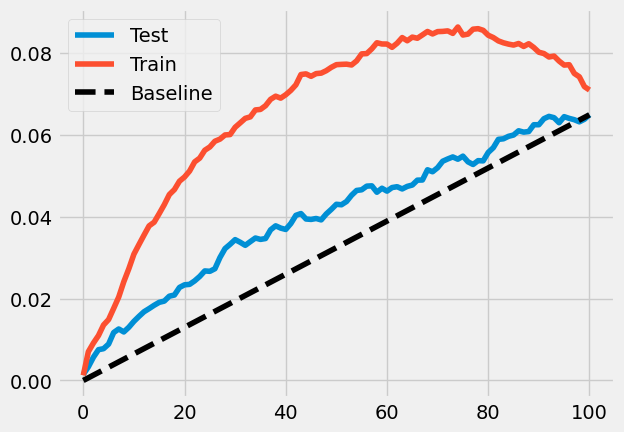

In [ ]:
gain_curve_test = cumulative_gain(test_pred, "cate", y="converted", t="em1")
gain_curve_train = cumulative_gain(train.assign(cate=cate_learner.predict(train[X])), "cate", y="converted", t="em1")
plt.plot(gain_curve_test, color="C0", label="Test")
plt.plot(gain_curve_train, color="C1", label="Train")
plt.plot([0, 100], [0, elast(test, "converted", "em1")], linestyle="--", color="black", label="Baseline")
plt.legend();

Как мы видим, оценка «plug and play» лучше случайной на тестовом наборе. Тем не менее, похоже, что она сильно переобучается, поскольку её эффективность на обучающем наборе значительно выше, чем на тестовом.

На самом деле, это один из самых больших недостатков данного метода преобразования целевой выборки. Преобразование целевой выборки обеспечивает значительную простоту, поскольку позволяет просто преобразовать целевую выборку и использовать любую оценку ML для прогнозирования неоднородных эффектов воздействия. За это приходится платить высокой дисперсией. Это связано с тем, что преобразованная целевая выборка представляет собой очень зашумлённую оценку индивидуального эффекта воздействия, и эта дисперсия переносится на вашу оценку. Это серьёзная проблема, если у вас не так много данных, но она должна быть менее серьёзной в приложениях с большими данными, где вы имеете дело с более чем 1 млн выборок.

**Случай непрерывного воздействия**

Ещё один очевидный недостаток метода целевого преобразования заключается в том, что он работает только для дискретных или бинарных воздействий. Это часто встречается в литературе по причинно-следственным выводам. Большая часть исследований посвящена случаю бинарного воздействия, но о непрерывном воздействии информации мало. Matheus Facure придумал то, что работает на практике, хотя подчёркивает, что у него нет по-настоящему серьёзного эконометрического исследования по этому вопросу.

Чтобы проиллюстрировать это, вернёмся к примеру с продажей мороженого. Там нам была поставлена задача оценить эластичность спроса по цене, чтобы мы могли лучше устанавливать цены на мороженое для оптимизации наших доходов. Напомним, что выборка событий в наборе данных представляет собой день, и мы хотим знать, когда люди менее чувствительны к повышению цен. Кроме того, помните, что в этом наборе данных цены назначаются случайным образом, а это значит, что нам не нужно беспокоиться о смещении данных.

In [ ]:
prices_rnd = pd.read_csv("./data/ice_cream_sales_rnd.csv")
prices_rnd.head()

,temp,weekday,cost,price,sales
0,25.8,1,0.3,7,230
1,22.7,3,0.5,4,190
2,33.7,7,1.0,5,237
3,23.0,4,0.5,5,193
4,24.4,1,1.0,3,252


In [ ]:
np.random.seed(123)
train, test = train_test_split(prices_rnd, test_size=0.3)
train.shape, test.shape

((3500, 5), (1500, 5))

Сначала рассмотрим простой случай, когда результат линейен в зависимости от воздействия. Предположим, у нас есть два типа дней: жаркие (жёлтые) и холодные (синие). В холодные дни люди более чувствительны к росту цен. Кроме того, с ростом цен спрос линейно падает.

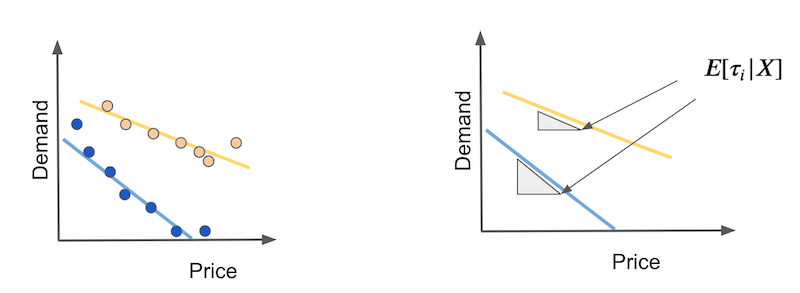

В этом случае CATE будет представлять собой наклон каждой линии спроса. Эти наклоны покажут нам, насколько упадёт спрос при любом повышении цены. Если эта зависимость действительно линейна, мы можем оценить эти эластичности с помощью коэффициента простой линейной регрессии отдельно для жарких и холодных дней.

$$
\hat{\tau(x)} = Cov(Y_i, T_i)/Var(T_i) = \dfrac{\sum(Y_i- \bar{Y})(T_i - \bar{T})}{\sum (T_i - \bar{T})^2}
$$

Вдохновившись этой оценкой, мы можем представить, как она будет выглядеть для отдельного объекта. Другими словами, что, если бы у нас было то же самое, заданное для каждого дня? Это было бы примерно так:

$
Y^*_i = (Y_i- \bar{Y})\dfrac{(T_i - \bar{T})}{\sigma^2_T}
$

Проще говоря, мы бы преобразовали исходную целевую величину, вычтя из неё среднее значение, затем умножив её на значение воздействия, из которого мы также вычли среднее значение. Наконец, мы бы разделили её на дисперсию воздействия. Вопрос теперь в следующем: работает ли это? На самом деле работает, и мы можем привести аналогичное доказательство, объясняющее, почему это работает, как и в двоичном случае.

Во-первых, обозначим $V_i = \dfrac{(T_i - \bar{T})}{\sigma^2_T}$. Обратите внимание, что $E[V_i|X_i=x]=0$, поскольку при случайном распределении $E[T_i|X_i=x]=\bar{T}$. Другими словами, для каждой области X $E[T_i]=\bar{T}$. Также $E[T_i V_i | X_i=x]=1$, поскольку $E[T_i(T_i - \bar{T})|X_i=x] = E[(T_i - \bar{T})^2|X_i=x]$, что является дисперсией воздействия. Наконец, при условной независимости (которую мы получаем бесплатно в случае случайного назначения воздействия), $E[T_i e_i | X_i=x] = E[T_i | X_i=x] E[e_i | X_i=x]$.

Чтобы показать, что это целевое преобразование работает, нам нужно помнить, что мы оцениваем параметр для локальной линейной модели $Y_i = \alpha + \beta T_i + e_i | X_i=x$.

В нашем примере это будут линейные модели для жарких и холодных дней. Здесь нас интересует параметр $\beta$, который является нашей условной эластичностью, или CATE. С учётом всего этого мы можем доказать, что

$
\begin{align}
E[Y^*_i|X_i=X] &= E[(Y_i-\bar{Y})V_i | X_i=x] \\
&= E[(\alpha + \beta T_i + e_i - \bar{Y})V_i | X_i=x] \\
&= \alpha E[V_i | X_i=x] + \beta E[T_i V_i | X_i=x] + E[e_i V_i | X_i=x] \\
&= \beta + E[e_i V_i | X_i=x] \\
&= \beta = \tau(x)
\end{align}
$

Помните, что это работает только при рандомизированном воздействии. Для нерандомизированного нам нужно заменить $\bar{T}$ на $M(X_i)$, где $M$ — это модель, которая оценивает $E[T_i|X_i=x]$.

$
Y^*_i = (Y_i- \bar{Y})\dfrac{(T_i - M(T_i))}{(T_i - M(T_i))^2}
$

Это гарантирует, что член $\alpha E[V_i | X_i=x]$ в третьей строке обратится в ноль, а член $E[T_i V_i | X_i=x]$ станет равен 1. Обратите внимание, что вам не обязательно стремиться к 1, если вы хотите упорядочить единицы по эффекту воздействия. Другими словами, если вы просто хотите узнать, в какие дни спрос более чувствителен к повышению цен, но вам не нужно знать, насколько, неважно, увеличены или уменьшены оценки $\beta$. В этом случае знаменатель можно опустить $Y^*_i = (Y_i- \bar{Y})(T_i - M(T_i))$.

Код на самом деле очень прост. Здесь у нас случайные назначения воздействия, поэтому нам не нужно строить модель, предсказывающую цены. Я также опускаю знаменатель, поскольку здесь меня интересует только порядок эффекта воздействия.

In [ ]:
y_star_cont = (train["price"] - train["price"].mean()) * (train["sales"] - train["sales"].mean())

cate_learner = LGBMRegressor(max_depth=3, min_child_samples=300, num_leaves=5)

np.random.seed(123)
cate_learner.fit(train[["temp", "weekday", "cost"]], y_star_cont)

cate_test_transf_y = cate_learner.predict(test[["temp", "weekday", "cost"]])

test_pred = test.assign(cate=cate_test_transf_y)
test_pred.sample(5)

На этот раз интерпретация CATE неинтуитивна. Поскольку мы убрали знаменатель из целевого преобразования, этот CATE, который мы видим, масштабируется по $Var(X)$. Тем не менее, этот прогноз должен довольно точно упорядочить эффект воздействия. Чтобы убедиться в этом, мы можем использовать кумулятивную кривую прироста, как и раньше.

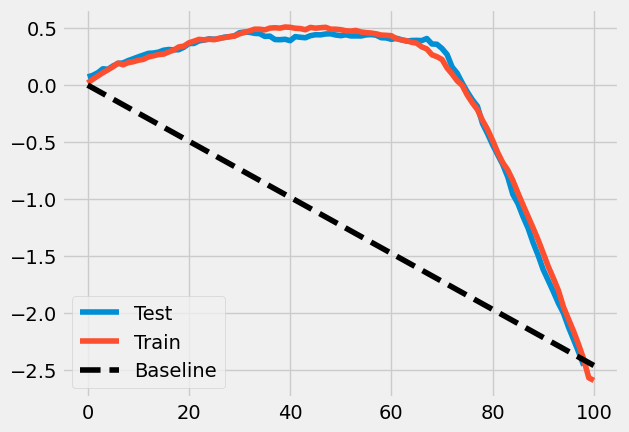

In [ ]:
gain_curve_test = cumulative_gain(test.assign(cate=cate_test_transf_y),
                                "cate", y="sales", t="price")

gain_curve_train = cumulative_gain(train.assign(cate=cate_learner.predict(train[["temp", "weekday", "cost"]])),
                                   "cate", y="sales", t="price")


plt.plot(gain_curve_test, label="Test")
plt.plot(gain_curve_train, label="Train")
plt.plot([0, 100], [0, elast(test, "sales", "price")], linestyle="--", color="black", label="Baseline")
plt.legend();

Для этих данных модель, похоже, намного лучше случайной. Более того, результаты обучения и тестирования довольно близки, поэтому дисперсия здесь не играет роли. Но это всего лишь характеристика данного набора данных. Если вы помните, в случае с бинарным воздействием этого не было. Там модель показала не очень хорошие результаты.

**Нелинейные эффекты воздействия**

Учитывая непрерывный случай, нам всё ещё нужно разобраться с проблемой. Мы предположили линейность эффекта воздействия. Однако это предположение крайне редко бывает обоснованным. Обычно эффекты воздействия достигают своего предела в той или иной форме. В нашем примере разумно предположить, что спрос будет снижаться быстрее при первых единицах повышения цены, но затем он будет падать медленнее.

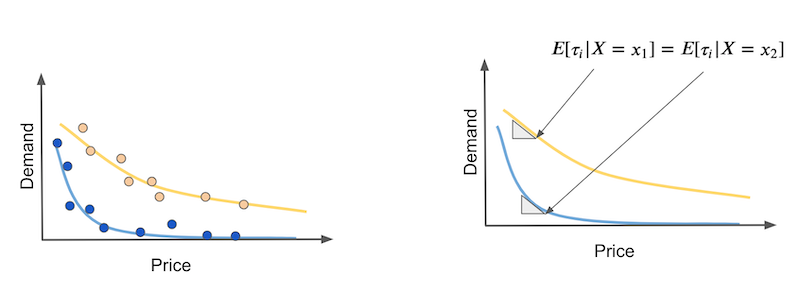

Проблема здесь в том, что **эластичность, или эффект воздействия, меняется вместе с самим воздействием**. В нашем примере эффект воздействия сильнее в начале кривой и ослабевает по мере роста цен. Предположим, что у вас есть два типа дней: жаркие (жёлтые) и холодные (синие), и мы хотим различить их с помощью причинно-следственной модели. Дело в том, что причинно-следственные модели должны предсказывать эластичность, но в нелинейном случае эластичность для жарких и холодных дней может быть одинаковой, если мы рассмотрим разные ценовые точки на кривой (правое изображение).

Простого решения этой проблемы нет. Matheus Facure предлагает представить функциональную форму эффекта воздействия и каким-то образом линеаризовать её. Например, спрос обычно имеет следующую функциональную форму, где более высокие значения $\alpha$s означают, что спрос падает быстрее с каждым повышением цены.

$
D_i = \dfrac{1}{P_i^{\alpha}}
$

Итак, если применить логарифмическое преобразование как к спросу $Y$, так и к ценам $T$, то должна получиться линейная функция.

$
\begin{align}
log(D)_i &= log\bigg(\dfrac{1}{P_i^{\alpha}}\bigg) \\
&= log(1) - log(P_i^{\alpha}) \\
&= log(1) - log(P_i^{\alpha}) \\
&= - \alpha * log(P_i) \\
\end{align}
$

Линеаризация не так проста, поскольку требует размышлений. Но вы можете попробовать разные варианты и найти лучший. Часто помогают такие методы, как логарифмы и квадратные корни.

#### Casual Impact

**Введение и Постановка Проблемы**

Определение причинно-следственного влияния рыночных интервенций — это **важная и актуальная задача** в эконометрике и маркетинге. Многие компании осознали, что систематическое использование метрик влияния для принятия стратегических решений может дать им конкурентное преимущество. Примером является использование "A/B экспериментов" для выявления наиболее эффективных рыночных воздействий с целью распределения ресурсов.

Однако существуют ситуации, когда **рандомизированный эксперимент невозможен**. Например, рекламные кампании часто запускаются по множеству каналов (онлайн и офлайн), что исключает измерение индивидуального воздействия. Кампании могут быть нацелены на целую страну, что запрещает использование географических контролей внутри этой страны. В таких случаях традиционные подходы, такие как разность разностей (difference-in-differences, DD), имеют **ограничения**.

Метод, предложенный в статье, **CausalImpact**, направлен на решение этой проблемы. Он позволяет **выводить причинно-следственное влияние** рыночной интервенции, такой как запуск нового продукта или начало рекламной кампании, на основе диффузионно-регрессионной модели пространства состояний.

**Ключевые преимущества подхода CausalImpact**:
*   **Оценка временной эволюции влияния**: В отличие от классических схем разности разностей, модели пространства состояний позволяют **выводить временную эволюцию приписываемого воздействия**.
*   **Байесовский подход**: Метод включает **эмпирические априорные распределения** для параметров в **полностью байесовской обработке**, а также использует **байесовское усреднение моделей** для построения наиболее подходящего синтетического контроля.
*   **Гибкость**: Он гибко учитывает **множественные источники вариации**, включая локальные тренды, сезонность и изменяющееся во времени влияние современных ковариат.

**Байесовские Структурные Временные Ряды (BSTS)**

Метод CausalImpact основан на **байесовских структурных моделях временных рядов (Bayesian Structural Time Series, BSTS)**, которые являются частным случаем моделей пространства состояний. Эти модели отличаются тем, что они могут гибко адаптироваться к различным предположениям о скрытом состоянии и процессах эмиссии, лежащих в основе наблюдаемых данных.

**Общая форма моделей пространства состояний** определяется парой уравнений:

1.  **Уравнение наблюдений (Observation Equation)**: Связывает наблюдаемые данные с латентным вектором состояния.
$
y_t = Z_t^{T}\alpha_t + \epsilon_{t}
$
2.  **Уравнение состояния (State Equation)**: Описывает эволюцию вектора состояния во времени.
$
\alpha_{t+1} = T_{t}\alpha_t + R_t \eta_t
$

Где:
*   $y_t$ — скалярное наблюдение в момент времени $t$ (например, продажи или посещения сайта).
*   $\alpha_t$ — $d$-мерный латентный вектор состояния в момент времени $t$.
*   $Z_t$ — $d$-мерный выходной вектор.
*   $T_t$ — $d × d$ матрица перехода, описывающая, как состояние $\alpha_t$ эволюционирует к $\alpha_{t+1}$.
*   $R_t$ — $d × q$ контрольная матрица.
*   $\epsilon_{t}$ — скалярная ошибка наблюдения, предполагаемая как $\epsilon_{t} ∼ N(0, σ^2_t)$, независимая от других неизвестных.
*   $η_t$ — $q$-мерная системная ошибка, предполагаемая как $η_t ∼ N(0, Q_t)$, независимая от других неизвестных.
*   $Q_t$ — $q × q$ матрица диффузии состояния.

Структурные модели временных рядов очень **гибкие и модульные**. Они гибкие в том смысле, что очень широкий класс моделей, включая все модели ARIMA, может быть записан в форме пространства состояний. Они модульные в том смысле, что латентное состояние, а также связанные с ним матрицы $Z_t, T_t, R_t$ и $Qt$ могут быть собраны из **компонентных подмоделей** для захвата важных особенностей данных. Обычно предполагается, что ошибки различных компонентных моделей состояния независимы, что позволяет формировать $\alpha_t$ путем конкатенации индивидуальных компонент состояния, а $T_t$ и $R_t$ становятся блочно-диагональными матрицами.

\\

**Компоненты состояния**:
Модель CausalImpact может включать следующие компоненты состояния:

*   **Локальный линейный тренд (Local linear trend)**:

  Эта компонента моделирует изменяющийся во времени уровень ($μ_t$) и его ожидаемое изменение (наклон $δ_t$).

  $μ_{t+1} = μ_t + δ_t + η_{μ,t}$

  $δ_{t+1} = δ_t + η_{δ,t}$
  
  где $η_{μ,t} ∼ N(0, σ^2_μ)$ и $η_{δ,t} ∼ N(0, σ^2_δ)$ — независимые ошибки.
  Это популярный выбор для моделирования трендов, так как он **быстро адаптируется к локальным вариациям**, что желательно для краткосрочных прогнозов. Существует также обобщение этой модели, где наклон демонстрирует стационарность вместо случайного блуждания, балансируя краткосрочную информацию с информацией из далекого прошлого.

*   **Сезонность (Seasonality)**:
  
  Эта компонента учитывает регулярные сезонные колебания в данных. Наиболее часто используемая модель в временной области:

  $γ_{t+1} =  - \displaystyle\sum_{s=0}^{S-2} γ_{t-s} + η_{γ,t}$

  где $S$ — количество сезонов (например, $S=7$ для дневного эффекта недели), а $γ_t$ обозначает их совместный вклад в наблюдаемый отклик $y_t$. Среднее значение $γ_{t+1}$ таково, что общий сезонный эффект равен нулю при суммировании за $S$ сезонов. Эта модель может быть обобщена для нескольких сезонных компонент с различными периодами.

*   **Современные ковариаты со статическими коэффициентами (Contemporaneous covariates with static coefficients)**:
  
  Контрольные временные ряды, которые не подвергались воздействию, **критически важны для получения точных контрфактических прогнозов**, поскольку они объясняют компоненты дисперсии, общие для ряда, включая эффекты других ненаблюдаемых причин. Линейная регрессия является естественным способом включения контрольных рядов в модель. В статической регрессии коэффициенты $β$ остаются постоянными. В байесовском подходе **нет необходимости фиксировать набор ковариат**, благодаря использованию **spike-and-slab априорного распределения**. Оно позволяет интегрировать апостериорную неопределенность относительно того, какие ковариаты включать и как сильно они должны влиять на прогнозы, что **помогает избежать переобучения**.

*   **Современные ковариаты с динамическими коэффициентами (Contemporaneous covariates with dynamic coefficients)**:
  
  Альтернативой статическим коэффициентам является регрессионная компонента с **динамическими коэффициентами регрессии** для учета изменяющихся во времени связей.
  
  $x^T_t β_t = \displaystyle \sum_{j=1}^J x_{j,t}β_{j,t}$

  $β_{j,t+1} = β_{j,t} + η_{β,j,t}$
  
  где $βj,t$ — коэффициент для $j$-го контрольного ряда, а $η_{β,j,t} ∼ N(0, σ^2_{βj})$ — ошибка случайного блуждания.
  
  Динамические коэффициенты полезны, когда предполагается, что **линейная связь между обрабатываемыми метриками и контролями меняется со временем**.


Структурные модели временных рядов позволяют гибко выбирать подходящие компоненты для тренда, сезонности и регрессии (статической или динамической). Например, наличие или отсутствие сезонности обычно очевидно при визуальном осмотре. Статические коэффициенты привлекательны, когда связь между контролями и обрабатываемой единицей была стабильной в прошлом, так как spike-and-slab априорное распределение может быть эффективно реализовано. Динамические коэффициенты используются, когда эта связь, как считается, меняется со временем.


На рисунке ниже представлена графическая модель для варианта модели пространства состояний со статической регрессией.
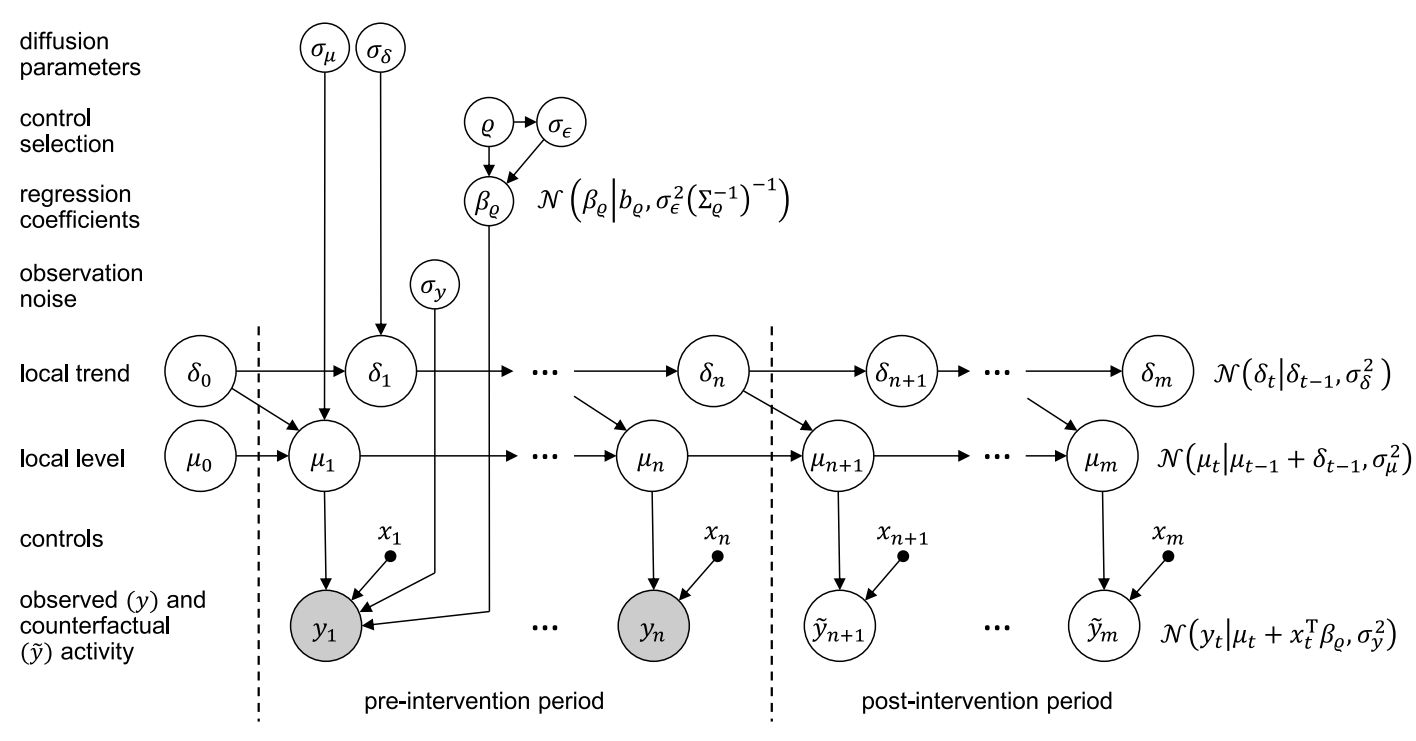

**Принцип работы метода CausalImpact**

Метод CausalImpact inferring причинно-следственное воздействие на основе диффузионно-регрессионной модели пространства состояний, которая **прогнозирует контрфактический отклик**, который произошел бы, если бы не было вмешательства. Он использует три основных шага: построение контрфактической модели, прогнозирование контрфактического сценария и оценку причинно-следственного эффекта.

**Источники информации для построения синтетического контроля**:
1.  **Поведение временного ряда самого отклика** до интервенции.
2.  **Поведение других временных рядов**, которые были предсказуемы для целевого ряда до интервенции (контрольные ряды).
3.  **Априорные знания** о параметрах модели в байесовской структуре.

Эти три источника информации объединяются с использованием модели временных рядов в пространстве состояний.

**Шаг 1: Построение контрфактической модели**

Этот шаг включает в себя **определение и обучение модели BSTS** на данных, предшествующих интервенции (тренировочный период), чтобы она могла точно предсказывать поведение целевого временного ряда $y_t$ в отсутствие вмешательства.

1.  **Выбор компонент состояния**

  Как обсуждалось выше, модель может включать компоненты для **тренда**, **сезонности** и **регрессии на современных ковариатах**. Выбор зависит от характеристик данных и предметной области.
    *   Например, для анализа рекламной кампании в статье использовалась комбинация **локального уровня** и **статической регрессионной компоненты**.
    *   При анализе симулированных данных использовалась **динамическая регрессионная компонента**.

2.  **Спецификация априорных распределений (Prior distributions)**:
    
  В байесовском подходе мы задаем априорные распределения $p(θ)$ для всех параметров модели $θ$ и $p(α_0|θ)$ для начальных значений состояния $α0$.

    *   **Для дисперсионных параметров**
    
      Типичное априорное распределение для дисперсии ($σ^2$) — это **обратное гамма-распределение** $\frac{1}{σ^2} ∼ G(\frac{ν}{2}, \frac{s}{2})$
    
      где $G(a, b)$ — гамма-распределение с ожиданием $a/b$. Параметры $ν$ и $s$ можно интерпретировать как априорную сумму квадратов и вес в единицах размера априорной выборки. Часто используются слабые, неинформативные априорные распределения (например, $ν=1$, $s/ν$ — малое значение).

    *   **Для коэффициентов регрессии (Spike-and-Slab prior)**
    
      Когда имеется много потенциальных ковариат (контрольных рядов $x_t$), модель сама выбирает наиболее подходящий набор с помощью **spike-and-slab априорного распределения**. Это распределение сочетает точечную массу в нуле (the "spike") для неизвестного подмножества нулевых коэффициентов с слабо информативным распределением на дополнительном наборе ненулевых коэффициентов (the "slab").
        Пусть $γ = (γ_1, ..., γ_J)$, где $γ_j = 1$, если $β_j ≠ 0$, и $γ_j = 0$ в противном случае. Пусть $β_γ$ обозначает ненулевые элементы вектора $β$.
        Априорное распределение факторизуется как:

        $p(γ, β, 1/σ^2_{ε}) = p(γ) p(σ^2_ε | γ) p(β_γ | γ,σ^2_ε)$

        *   **"Spike" (выбор переменных)**: Часто используется произведение независимых распределений Бернулли:

        $p(γ) = \displaystyle\prod_{j=1}^J π_j^{γ_j} (1 - π_j)^{1-γ_j}$

        где $π_j$ — априорная вероятность включения регрессора $j$ в модель. Значения $π_j$ можно определить, задав ожидаемый размер модели $M$ (например, $π_j = M/J$).

        *   **"Slab" (распределение ненулевых коэффициентов)**: Используется сопряженное нормальное-обратное гамма-распределение:
        
        $β_γ | σ^2_ε ∼ N(b_γ, σ^2_ε (\sum^{-1}_γ)^{-1})$

        $\frac{1}{σ^2_ε} ∼ G(ν_ε/2, s_ε/2)$

        Вектор $b_γ$ кодирует априорное ожидание значения каждого элемента $β$ (часто $b_γ = 0$). Параметры $ν_ε$ и $s_ε$ определяются ожидаемым $R^2$ и количеством наблюдений, которым присваивается вес.

3.  **Апостериорный вывод (Posterior Inference)**

  Поскольку замкнутых форм для апостериорных распределений не существует, для вывода используется **алгоритм Монте-Карло по Марковским цепям (MCMC)**, в частности, **сэмплер Гиббса**.
    *   **Шаг увеличения данных (Data-augmentation step)**: симулирует $p(α|y_{1:n}, θ)$ (последовательность состояний $α$ при заданных данных и параметрах) с использованием алгоритма симуляции сглаживателя от Дурбина и Купмана (2002). Этот алгоритм является линейным по количеству временных точек и квадратичным по размерности пространства состояний.
    *   **Шаг симуляции параметров (Parameter-simulation step)**: симулирует $p(θ|y_{1:n}, α)$ (параметры $θ$ при заданных данных и состояниях). Для большинства компонент это просто благодаря сопряженности априорных распределений. Для статических коэффициентов регрессии $β$ симуляция включает выбор $γ$ из $p(γ|y_{1:n})$ с последующим семплированием $β$ и $σ^2_ε$ из сопряженных формул.

**Шаг 2: Прогнозирование контрфактического сценария**

После обучения модели на пред-интервенционных данных и получения апостериорных выборок параметров ($θ$) и состояний ($α$), следующим шагом является **прогнозирование контрфактического временного ряда**. Контрфактический сценарий — это **ненаблюдаемый рыночный отклик $ỹ_{n+1:m}$**, который произошел бы на обработанном рынке после интервенции в отсутствие воздействия.

1.  **Апостериорное предиктивное распределение**

  Прогнозирование осуществляется путем симуляции из **апостериорного предиктивного распределения**:
  $p(ỹ_{n+1:m} | y_{1:n}, x_{1:m})$

  Это распределение определяется для той части временного ряда, которая является ненаблюдаемой, то есть для контрфактических откликов $ỹ_{n+1}, ..., ỹ_m$.
  **Важно**: Плотность обусловлена только наблюдаемыми данными (до интервенции для целевого ряда $y_{1:n}$) и активностью во всех контрольных рынках (как до, так и во время интервенции $x_{1:m}).

2.  **Байесовское усреднение моделей (Bayesian Model Averaging)**

   Модель **не фиксируется на каком-либо конкретном наборе ковариат** или точечных оценках их коэффициентов. Вместо этого, благодаря байесовскому усреднению моделей, **неопределенность относительно выбора ковариат и их влияния интегрируется**. Это помогает избежать произвольного выбора и переобучения.
3.  **Когерентность прогнозов**

  Апостериорная предиктивная плотность определяется как **когерентное (совместное) распределение** по всем контрфактическим точкам данных, а не как набор поточечных одномерных распределений. Это гарантирует, что сериальная структура, определенная на данных до интервенции, правильно распространяется на траекторию контрфактов. Это крайне важно при формировании сводных статистик, таких как **кумулятивный эффект**.


**Шаг 3: Оценка каузального эффекта**

Имея выборки из апостериорного предиктивного распределения контрфактической активности, можно легко получить выборки **причинно-следственного эффекта**.

1.  **Поточечное влияние (Pointwise impact)**
  
  Для каждой выборки $τ$ и для каждого момента времени $t = n+1, ..., m$ (период после интервенции) поточечное влияние $φ^{(τ)}_t$ определяется как разность между наблюдаемым значением $y_t$ и предсказанным контрфактическим значением $ỹ^{(τ)}_t$: $φ^{(τ)}_t := y_t - ỹ^{(τ)}_t$
    
  Это дает выборки из приближенной апостериорной предиктивной плотности эффекта, приписываемого интервенции.

2.  **Кумулятивное влияние (Cumulative impact)**

  Часто желательно понять **кумулятивный эффект** интервенции с течением времени. С использованием полученных выборок влияния $φ^{(τ)}_t$ можно вычислить кумулятивную сумму для каждой выборки $τ$:

  $\displaystyle\sum_{(t'=n+1)}^t φ^{(τ)}_{t'} \qquad ∀t = n+1, ..., m$
  
  Эта кумулятивная сумма полезна, когда $y$ представляет собой **потоковую величину**.

3.  **Среднее влияние (Running average impact)**

  Если $y$ представляет **запасовую величину** (например, общее количество клиентов), кумулятивная сумма может быть неинтерпретируемой. В этом случае можно рассчитать среднее влияние:
  $\frac{1}{t - n} \displaystyle \sum_{t'=n+1}^t φ^{(τ)}_{t'}  \qquad   ∀t = n+1, ..., m$
  
  Среднее влияние всегда интерпретируемо, но более зависимо от длины постинтервенционного периода.


Таким образом, CausalImpact предоставляет **мощный и гибкий байесовский фреймворк** для оценки причинно-следственного влияния в условиях, когда рандомизированные эксперименты невозможны или непрактичны, используя структурные модели временных рядов и продвинутые байесовские методы для построения синтетических контролей и вывода апостериорных распределений для эффекта.

In [ ]:
!pip install -q pycausalimpact
import pandas as pd
from causalimpact import CausalImpact
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(font_scale=1)

df = pd.read_excel('amt_key.xlsx')
df.columns = ['date', 'cred_amt', 'key_value_perc']
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df.head(3)

,cred_amt,key_value_perc
date,,
2013-09-30,720230,0.055
2013-10-31,776353,0.055
2013-11-30,736822,0.055


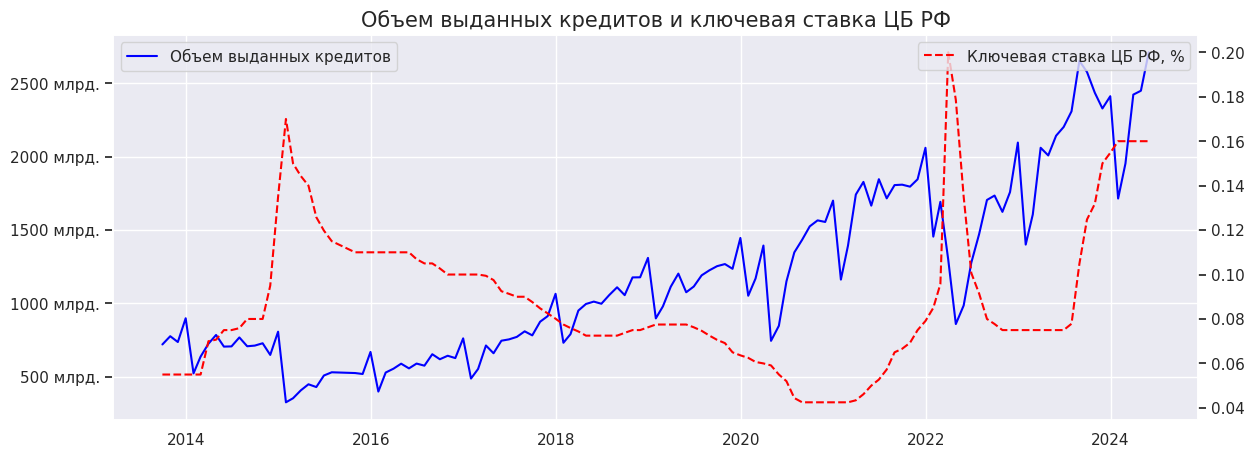

In [ ]:
import warnings as w
w.filterwarnings('ignore')

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax1.plot(df['cred_amt'], color='blue', label='Объем выданных кредитов, млн. руб.');
ax2.plot(df['key_value_perc'], color='red', label='Ключевая ставка ЦБ РФ, %', ls='--');
ax1.legend(['Объем выданных кредитов']);
ax1.set_yticklabels(['{:.0f} млрд.'.format(x*1000000/1000000000) for x in ax1.get_yticks()])
ax2.legend(['Ключевая ставка ЦБ РФ, %'], loc='upper right');
ax2.grid(False)
plt.title('Объем выданных кредитов и ключевая ставка ЦБ РФ', fontsize=15);

Теперь определим период для оценки влияния ключевой ставки на объем выданных кредитов. Для примера возьмем ситуацию в марте 2022 года, когда ЦБ РФ резко поднял ключевую ставку с 9,58% до 20,00% и оценим, насколько уменьшился объем выданных кредитов относительно ситуации, если бы ЦБ РФ не поднимал ставку.

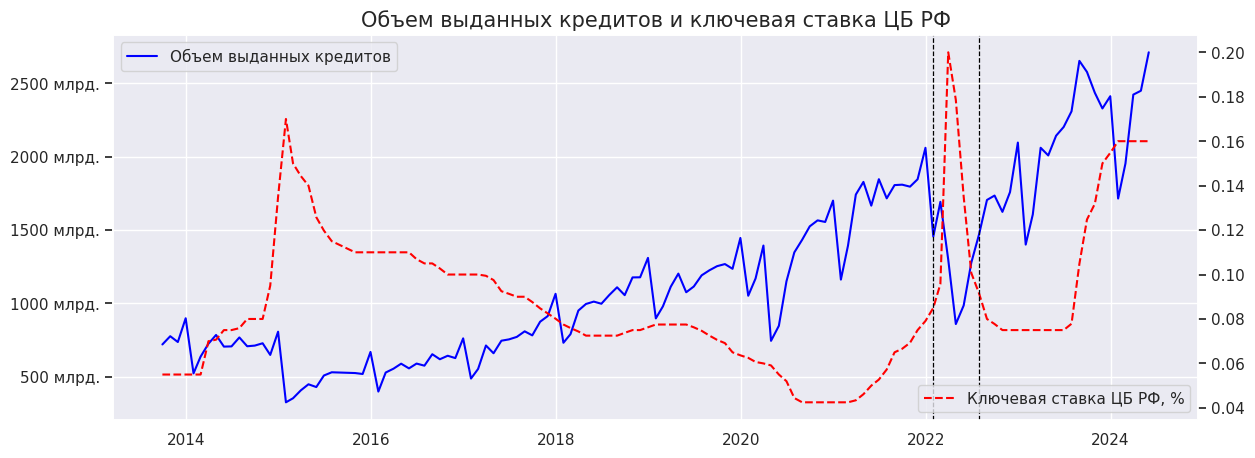

In [ ]:
import warnings as w
w.filterwarnings('ignore')

fig, ax1 = plt.subplots(figsize=(14, 5))
ax2 = ax1.twinx()

ax1.plot(df['cred_amt'], color='blue', label='Объем выданных кредитов, млн. руб.');
ax2.plot(df['key_value_perc'], color='red', label='Ключевая ставка ЦБ РФ, %', ls='--');
ax1.legend(['Объем выданных кредитов']);
ax1.set_yticklabels(['{:.0f} млрд.'.format(x*1000000/1000000000) for x in ax1.get_yticks()])
ax2.legend(['Ключевая ставка ЦБ РФ, %'], loc='lower right');
ax2.grid(False)
plt.title('Объем выданных кредитов и ключевая ставка ЦБ РФ', fontsize=15);
plt.axvline(pd.to_datetime('2022-01-31'), color='black', ls='--', lw=0.9);
plt.axvline(pd.to_datetime('2022-07-31'), color='black', ls='--', lw=0.9);

Для предсказания Causal Impact использует Линейную регрессию и для нее, как и для любой модели, действует правило – чем больше данных, тем лучше прогноз. Поэтому создадим дополнительные предикторы (признаки) для нашей модели на основе тех данных, которые у нас есть. Для этого я создал функцию create_features.

In [ ]:
def create_features(df_in, lags=3, target='cred_amt'):
    tmp = df_in.copy()
    tmp['day'] = tmp.index.day
    tmp['year'] = tmp.index.year
    tmp['month'] = tmp.index.month
    tmp['month_to_new_year'] = 12 - tmp.index.month

    tmp['rolling_mean_{}'.format(lags)] = tmp[target].rolling(lags, closed='left').mean()
    for lag in range(1, lags+1):
        tmp['lag_{}'.format(lag)] = tmp[target].shift(lag)

    return tmp

train_data = create_features(df).dropna()
train_data.head()

,cred_amt,key_value_perc,day,year,month,month_to_new_year,rolling_mean_3,lag_1,lag_2,lag_3
date,,,,,,,,,,
2013-12-31,898756,0.055000,31,2013,12,0,744468.333333,736822.0,776353.0,720230.0
2014-01-31,523223,0.055000,31,2014,1,11,803977.000000,898756.0,736822.0,776353.0
2014-02-28,637611,0.055000,28,2014,2,10,719600.333333,523223.0,898756.0,736822.0
2014-03-31,725301,0.070000,31,2014,3,9,686530.000000,637611.0,523223.0,898756.0
2014-04-30,784935,0.070682,30,2014,4,8,628711.666667,725301.0,637611.0,523223.0


Также для точности добавим такой показатель как количество населения России. Ведь население росло, а от этого и рос объем выданных кредитов. Данные о количестве населения я взял из Росстата (https://rosstat.gov.ru/storage/mediabank/Popul_1897+.xlsx).

In [ ]:
pop = pd.read_excel('rf_population.xlsx')

train_index = train_data.index
train_data = train_data.merge(pop, left_on='year', right_on='date')
train_data.index = train_index

train_data.head()

,cred_amt,key_value_perc,day,year,month,month_to_new_year,rolling_mean_3,lag_1,lag_2,lag_3,...,city_population_x,village_population_x,city_pop_perc_x,village_pop_perc_x,date_y,population_y,city_population_y,village_population_y,city_pop_perc_y,village_pop_perc_y
date,,,,,,,,,,,,,,,,,,,,,
2013-12-31,898756,0.055000,31,2013,12,0,744468.333333,736822.0,776353.0,720230.0,...,106.4,37.2,74,26,2013,143.6,106.4,37.2,74,26
2014-01-31,523223,0.055000,31,2014,1,11,803977.000000,898756.0,736822.0,776353.0,...,106.9,37.1,74,26,2014,144.0,106.9,37.1,74,26
2014-02-28,637611,0.055000,28,2014,2,10,719600.333333,523223.0,898756.0,736822.0,...,106.9,37.1,74,26,2014,144.0,106.9,37.1,74,26
2014-03-31,725301,0.070000,31,2014,3,9,686530.000000,637611.0,523223.0,898756.0,...,106.9,37.1,74,26,2014,144.0,106.9,37.1,74,26
2014-04-30,784935,0.070682,30,2014,4,8,628711.666667,725301.0,637611.0,523223.0,...,106.9,37.1,74,26,2014,144.0,106.9,37.1,74,26


**Важно отметить:** При подаче данных в пакет Causal Impact, мы должны соблюдать следующее правило. В индексе наших данных должна быть дата, первым столбцом должен идти целевой показатель, а последующими столбцами должны быть признаки.

Данные подготовлены, осталось всего ничего! Используем Causal Impact для оценки эффекта от повышения ключевой ставки.
Для начала импортируем библиотеку и зададим временные рамки

Здесь training_start и training_end (включительно) – обозначают период до возникновения события. treatment_start и treatment_end – обозначают период, когда событие продолжалось.

Нам остается лишь подать данные в функцию CausalImpact:

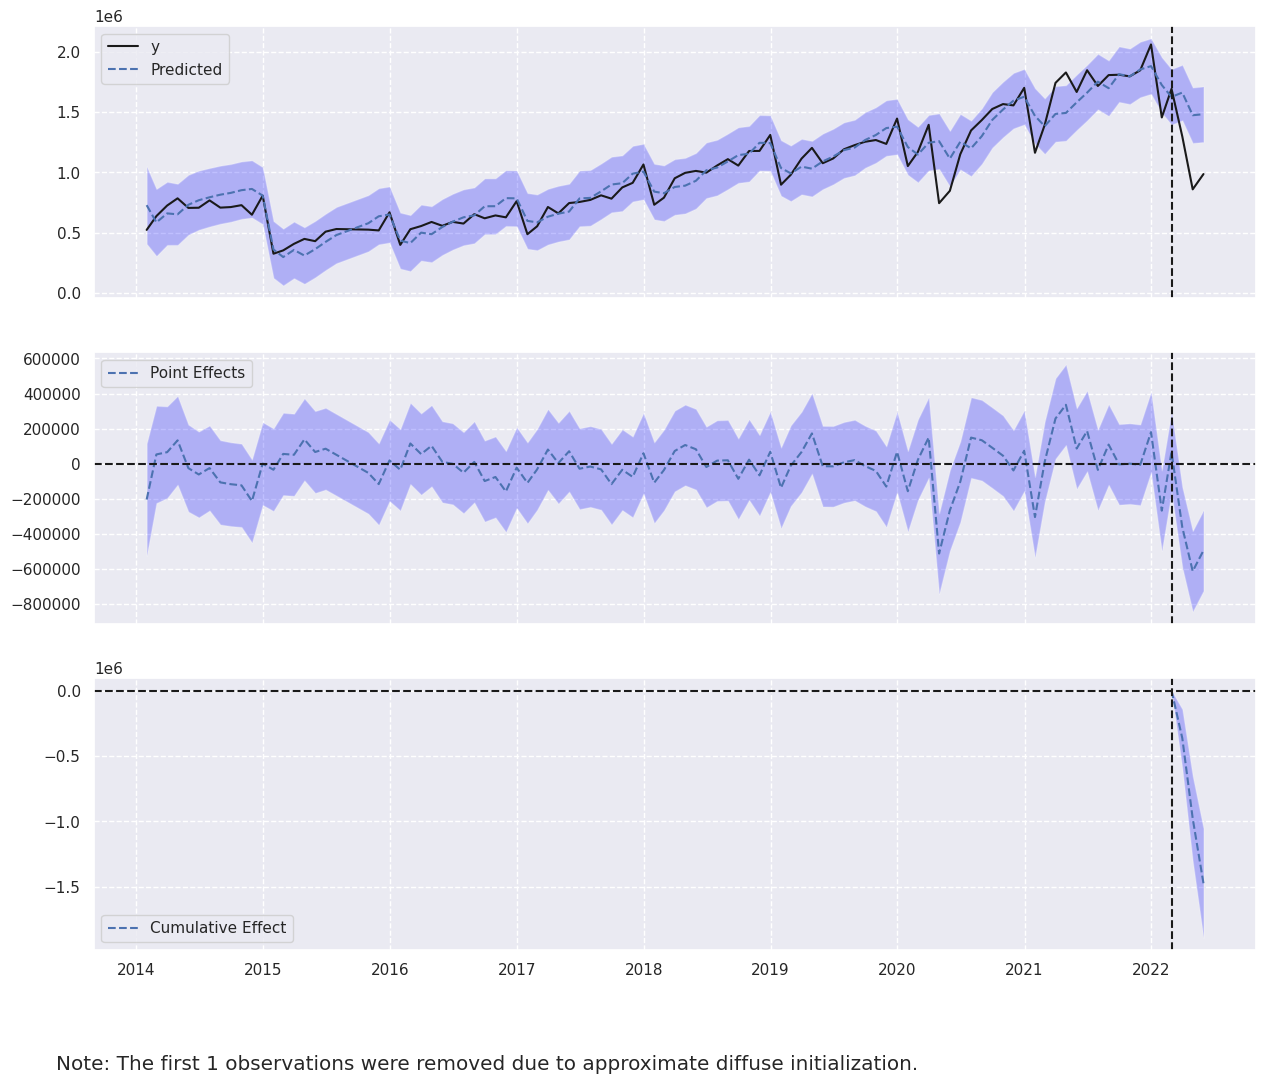

In [ ]:
from causalimpact import CausalImpact
import warnings as w
w.filterwarnings('ignore')

training_start = '2013-12-31'
training_end = '2022-02-28'
treatment_start = '2022-03-31'
treatment_end = '2022-05-31'

impact = CausalImpact(
    train_data,
    pre_period = [training_start, training_end],
    post_period = [treatment_start, treatment_end]
)

# После того, как функция приняла наши
# данные и обучила линейную регрессию
# на периоде до возникновения события,
# мы можем построить графики с помощью следующей команды:

impact.plot();

In [ ]:
print(impact.summary())

Posterior Inference {Causal Impact}
                          Average            Cumulative
Actual                    1047795.67         3143387.0
Prediction (s.d.)         1538883.6 (71042.55)4616650.79 (213127.64)
95% CI                    [1398625.64, 1677107.3][4195876.93, 5031321.91]

Absolute effect (s.d.)    -491087.93 (71042.55)-1473263.79 (213127.64)
95% CI                    [-629311.64, -350829.98][-1887934.91, -1052489.93]

Relative effect (s.d.)    -31.91% (4.62%)    -31.91% (4.62%)
95% CI                    [-40.89%, -22.8%]  [-40.89%, -22.8%]

Posterior tail-area probability p: 0.0
Posterior prob. of a causal effect: 100.0%

For more details run the command: print(impact.summary('report'))


In [ ]:
print(impact.summary('report'))

Analysis report {CausalImpact}


During the post-intervention period, the response variable had
an average value of approx. 1047795.67. By contrast, in the absence of an
intervention, we would have expected an average response of 1538883.6.
The 95% interval of this counterfactual prediction is [1398625.64, 1677107.3].
Subtracting this prediction from the observed response yields
an estimate of the causal effect the intervention had on the
response variable. This effect is -491087.93 with a 95% interval of
[-629311.64, -350829.98]. For a discussion of the significance of this effect,
see below.


Summing up the individual data points during the post-intervention
period (which can only sometimes be meaningfully interpreted), the
response variable had an overall value of 3143387.0.
By contrast, had the intervention not taken place, we would have expected
a sum of 4616650.79. The 95% interval of this prediction is [4195876.93, 5031321.91].


The above results are given in terms of absolute